# 01. Научный вопрос, выборка и методика

**Насколько правила условной доступности и качества METAR изменяют покрытие
и состав информации на C40 в фиксированной европейской выборке?**

Весь корпус: 6 331 485 событий и 18 349 меток GoA, 19 аэропортов.
Ретроспективный анализ свойств данных, без обучения модели. Основной сценарий
согласован ранее; исследовательские сценарии зафиксированы до этих расчетов.

## Временной выбор

Для события i время C40 обозначено t_i, время наблюдения сообщения j - o_j.
Предполагаемая задержка d не равна измеренному времени получения.

$$j^*(i;d)=\arg\max_j\{o_j:o_j+d<t_i\}.$$

Для предельной давности a покрытие наблюдениями:

$$A_i(a,d)=\mathbf1\{j^*\text{ однозначен},\ t_i-o_{j^*}\leq a\}.$$

Проверка основного текста Q_j и числовая маска M_jk дают:

$$U_i=A_iQ_{j^*},\qquad
x^{model}_{ik}=\begin{cases}x_{j^*k},&U_i=1, M_{j^*k}=0;\\
\mathrm{NA},&\text{иначе}.\end{cases}$$

Числовая маска не уничтожает все поля строки; непроверенный основной блок
оставляет все модельные погодные поля неизвестными. Отсутствующая порывная
группа не означает нулевой порыв. COR не является погодным явлением.


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
BASE=Path.cwd().resolve().parent
PROJECT=BASE.parents[1]
R,F=BASE/'reports',BASE/'figures'
GREEN,RED='#00897B','#D65A4A'
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.grid':True,'grid.alpha':.15,'axes.spines.top':False,'axes.spines.right':False})
def sha(path):
    with path.open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
    plt.close()
manifest=json.loads((R/'02_study_manifest.json').read_text(encoding='utf8'))
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==manifest['input_sha256']
assert sha(BASE/'protocol.md')==manifest['protocol_sha256']
assert manifest['primary_reproduced'] and manifest['all_rows_once'] and not manifest['training_executed']
summary=pd.read_csv(R/'02_scenario_summary.csv')
strata=pd.read_csv(R/'02_scenario_strata.csv')
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',50)


,name,age,delay,include_cor
0,primary,60,15,True
1,delay0,60,0,True
2,delay5,60,5,True
3,delay30,60,30,True
4,age30,30,15,True
5,age90,90,15,True
6,no_cor,60,15,False


,GoA,rows,observation,usable,cor_usable
0,False,6313136,6305612,6304267,274146
1,True,18349,18326,18319,1040


,airport,GoA,rows,usable,usable_percent
0,EDDB,False,147909,147858,99.965519
1,EDDB,True,427,427,100.000000
2,EDDF,False,603076,602922,99.974464
3,EDDF,True,1884,1884,100.000000
4,EDDM,False,441910,441755,99.964925
5,EDDM,True,1293,1292,99.922660
6,EGCC,False,87129,87105,99.972455
7,EGCC,True,306,306,100.000000
8,EGLL,False,629318,629088,99.963452
9,EGLL,True,2400,2400,100.000000


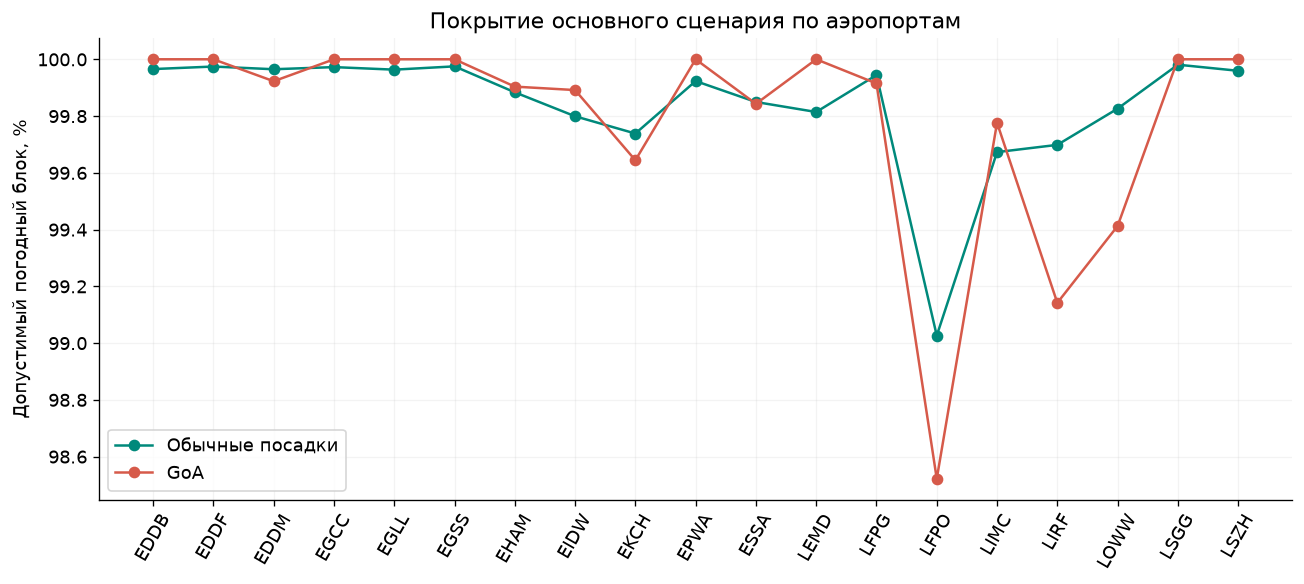

In [2]:
display(pd.DataFrame(manifest['scenarios']))
primary=strata.loc[strata.scenario.eq('primary')]
display(primary.groupby('GoA')[['rows','observation','usable','cor_usable']].sum().reset_index())
airport=primary.groupby(['airport','GoA'])[['rows','usable']].sum().reset_index()
airport['usable_percent']=100*airport.usable/airport.rows
display(airport)
fig,ax=plt.subplots(figsize=(11,5))
for label,color,title in [(False,GREEN,'Обычные посадки'),(True,RED,'GoA')]:
    group=airport.loc[airport.GoA.eq(label)].set_index('airport').sort_index()
    ax.plot(group.index,group.usable_percent,marker='o',color=color,label=title)
ax.set(ylabel='Допустимый погодный блок, %',title='Покрытие основного сценария по аэропортам')
ax.tick_params(axis='x',rotation=60)
ax.legend()
save('01_primary_airport_coverage')


## Причины недопустимости основного блока

Знаменатель - все события. Причины взаимоисключающие; это не классификация
причин отсутствия каждого отдельного числового поля.


,GoA,reason,rows
0,False,older_than_limit,7524
1,False,unverified_core,1345
2,False,usable,6304267
3,True,older_than_limit,23
4,True,unverified_core,7
5,True,usable,18319


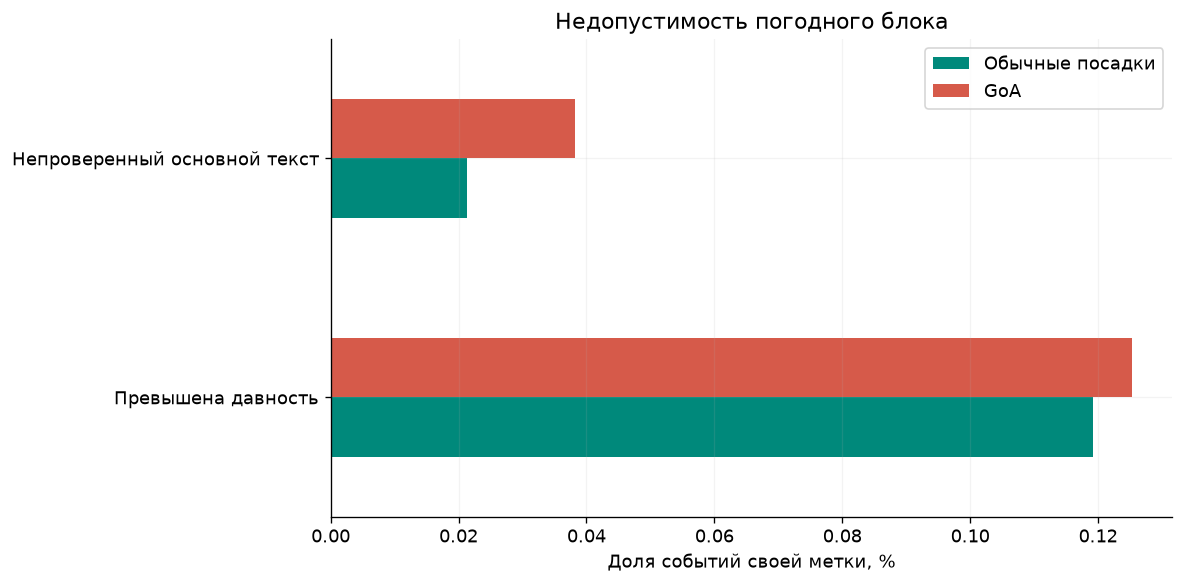

,season,GoA,rows,usable,usable_percent
0,DJF,False,1558154,1555994,99.861374
1,DJF,True,5188,5178,99.807247
2,JJA,False,1568554,1566756,99.885372
3,JJA,True,4197,4191,99.857041
4,MAM,False,1621083,1618814,99.860032
5,MAM,True,4758,4752,99.873897
6,SON,False,1565345,1562703,99.831219
7,SON,True,4206,4198,99.809796


In [3]:
reasons=pd.read_csv(R/'03_missing_reasons.csv')
counts=reasons.loc[reasons.scenario.eq('primary')].groupby(['GoA','reason']).rows.sum().reset_index()
display(counts)
excluded=counts.loc[counts.reason.ne('usable')]
fig,ax=plt.subplots(figsize=(10,5))
pivot=excluded.pivot(index='reason',columns='GoA',values='rows').fillna(0)
for label in pivot.columns:
    pivot[label]=100*pivot[label]/primary.loc[primary.GoA.eq(label),'rows'].sum()
pivot.rename(index={'no_previous_report':'Нет предыдущего сообщения','ambiguous_time':'Неоднозначное время',
    'older_than_limit':'Превышена давность','unverified_core':'Непроверенный основной текст'}).plot.barh(ax=ax,color=[GREEN,RED])
ax.set(xlabel='Доля событий своей метки, %',ylabel='',title='Недопустимость погодного блока')
ax.legend(['Обычные посадки','GoA'])
save('02_primary_missing_reasons')
season=primary.groupby(['season','GoA'])[['rows','usable']].sum().reset_index()
season['usable_percent']=100*season.usable/season.rows
display(season)


Источник и популяция уже отобраны предыдущим исследованием. Это
покрытие внутри фиксированного аналитического входа, не всех реальных посадок.
Сезоны DJF/MAM/JJA/SON - календарные группы месяцев по UTC. Изменение состава
аэропортов и лет не позволяет трактовать различия как причинный сезонный эффект.
Полные расчеты по событиям воспроизводятся scripts/run_study.py.
